In [1]:
from pathlib import Path

import joblib
import numpy as np

from scipy.ndimage import gaussian_filter, gaussian_laplace
from skimage.filters import sobel
from skimage.io import imread

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from matplotlib import pyplot as plt

from utils import crop_extractor, extract_pixel_features

In [2]:
data_dir = Path("/home/xgupke/Documents/projects/EmmaElinTrombocytes/datafiles/images")
labels_dir = data_dir / "labels"
images_dir = data_dir / "rare_granules"
model_dir = Path("/home/xgupke/Documents/projects/EmmaElinTrombocytes/pixel_classifier/runs/3")
csv_name = "rare_granules_raw_correct.csv"

In [3]:
labels_dict = {
    1: "granule",
    2: "tail",
    3: "spike"
}

In [4]:
with open(data_dir / "test_images.txt", "r") as f:
    test_images = [line.strip() for line in f if line.strip()]

In [5]:
test_images

['40135_J5_new_x4300_-10um_0081.png',
 '40135_E4_new_x4300_-10um_0044.png',
 '40135_G1_x4300_-10um_0033.png',
 '40135_E4_new_x4300_-10um_0001.png']

In [6]:
# import classifier and classify one input image

# def load_pixel_classifier(data_dir):
#     model_path = Path(data_dir) / "models_px" / "random_forest_px.joblib"
#     return joblib.load(model_path)


def classify_image(
    image,
    labels,
    stats,
    rf,
    sigma_fractions=(0.10, 0.20, 0.35),
    truncate=4.0,
    batch_size=500_000,
):
    """
    Extract pixel features and classify every pixel with the trained
    random forest.

    Parameters
    ----------
    image : np.ndarray, shape (Y, X)
        Grayscale input image.

    labels : np.ndarray, shape (Y, X)
        Ground-truth labels. Required by extract_pixel_features().
        These are NOT used for prediction.

    stats : dict
        Same statistics used when generating the training features.

    rf : RandomForestClassifier
        Trained random forest.

    batch_size : int
        Number of pixels predicted at once.

    Returns
    -------
    prediction : np.ndarray, shape (Y, X)
        Predicted label for every pixel.
    """

    # ------------------------------------------------------------
    # 1. Extract exactly the same features used for training
    # ------------------------------------------------------------

    feature_map, data, feature_names, sigmas, kernel_sizes = (
        extract_pixel_features(
            image=image,
            labels=labels,
            stats=stats,
            sigma_fractions=sigma_fractions,
            truncate=truncate,
        )
    )

    # data shape:
    # (Y * X, n_features + 1)
    #
    # Last column is ground-truth label, so don't give it to RF.
    X = data[:, :-1]


    # ------------------------------------------------------------
    # 2. Check feature count
    # ------------------------------------------------------------

    if X.shape[1] != rf.n_features_in_:
        raise ValueError(
            f"Feature mismatch: image produced {X.shape[1]} features, "
            f"but RF expects {rf.n_features_in_}."
        )


    # ------------------------------------------------------------
    # 3. Predict in batches
    # ------------------------------------------------------------

    prediction_flat = np.empty(
        X.shape[0],
        dtype=np.uint8,
    )

    for start in range(0, X.shape[0], batch_size):

        end = min(start + batch_size, X.shape[0])

        prediction_flat[start:end] = rf.predict(
            X[start:end]
        )


    # ------------------------------------------------------------
    # 4. Put pixels back into image shape
    # ------------------------------------------------------------

    prediction = prediction_flat.reshape(image.shape)

    return prediction

In [7]:
rf = joblib.load(model_dir / "random_forest_px.joblib")

In [8]:
# RUN 1

stats = {'granule': {'area': {'mean': 3023.387755102041, 'std': 1424.5535042183128},
  'major': {'mean': 61.7378022513564, 'std': 14.393787620831342},
  'minor': {'mean': 59.261608845675234, 'std': 13.969764691541528}},
 'tail': {'area': {'mean': 5164.75, 'std': 1701.2770460745069},
  'major': {'mean': 135.5374821410419, 'std': 32.46597350297029},
  'minor': {'mean': 53.49986584526819, 'std': 11.57409858121953}},
 'spike': {'area': {'mean': 3468.222222222222, 'std': 827.2504360534465},
  'major': {'mean': 70.23458449459747, 'std': 8.674841306071444},
  'minor': {'mean': 62.524790022941524, 'std': 8.480135598165038}}}

In [9]:
# RUN 2

{'granule': {'area': {'mean': 3151.027777777778, 'std': 1537.187411514056},
  'major': {'mean': 62.867866551930625, 'std': 15.294805029711885},
  'minor': {'mean': 60.40408048582818, 'std': 14.748075934836761}},
 'tail': {'area': {'mean': 5215.8125, 'std': 1597.741774300137},
  'major': {'mean': 136.5095380035434, 'std': 24.866662142255922},
  'minor': {'mean': 53.52832171695538, 'std': 11.810704479208846}},
 'spike': {'area': {'mean': 3380.5714285714284, 'std': 800.8063538250246},
  'major': {'mean': 69.24586366600968, 'std': 9.056212796425156},
  'minor': {'mean': 61.7448437695596, 'std': 8.242261028160263}}}

{'granule': {'area': {'mean': 3151.027777777778, 'std': 1537.187411514056},
  'major': {'mean': 62.867866551930625, 'std': 15.294805029711885},
  'minor': {'mean': 60.40408048582818, 'std': 14.748075934836761}},
 'tail': {'area': {'mean': 5215.8125, 'std': 1597.741774300137},
  'major': {'mean': 136.5095380035434, 'std': 24.866662142255922},
  'minor': {'mean': 53.52832171695538, 'std': 11.810704479208846}},
 'spike': {'area': {'mean': 3380.5714285714284, 'std': 800.8063538250246},
  'major': {'mean': 69.24586366600968, 'std': 9.056212796425156},
  'minor': {'mean': 61.7448437695596, 'std': 8.242261028160263}}}

In [10]:
# RUN 3
{'granule': {'area': {'mean': 3207.872340425532, 'std': 1439.944289953996},
  'major': {'mean': 63.813458639186834, 'std': 14.283216433650656},
  'minor': {'mean': 61.108846581319675, 'std': 13.73687069279649}},
 'tail': {'area': {'mean': 5126.888888888889, 'std': 1581.5119309237984},
  'major': {'mean': 133.9598308232208, 'std': 24.707982911400716},
  'minor': {'mean': 53.65386055209033, 'std': 11.865201433044074}},
 'spike': {'area': {'mean': 3358.625, 'std': 751.3328053366231},
  'major': {'mean': 69.49213577902589, 'std': 8.49633250955459},
  'minor': {'mean': 61.51777997402371, 'std': 7.733299054736629}}}

{'granule': {'area': {'mean': 3207.872340425532, 'std': 1439.944289953996},
  'major': {'mean': 63.813458639186834, 'std': 14.283216433650656},
  'minor': {'mean': 61.108846581319675, 'std': 13.73687069279649}},
 'tail': {'area': {'mean': 5126.888888888889, 'std': 1581.5119309237984},
  'major': {'mean': 133.9598308232208, 'std': 24.707982911400716},
  'minor': {'mean': 53.65386055209033, 'std': 11.865201433044074}},
 'spike': {'area': {'mean': 3358.625, 'std': 751.3328053366231},
  'major': {'mean': 69.49213577902589, 'std': 8.49633250955459},
  'minor': {'mean': 61.51777997402371, 'std': 7.733299054736629}}}

In [11]:
test_images

['40135_J5_new_x4300_-10um_0081.png',
 '40135_E4_new_x4300_-10um_0044.png',
 '40135_G1_x4300_-10um_0033.png',
 '40135_E4_new_x4300_-10um_0001.png']

In [12]:
crops = crop_extractor(test_images, images_dir, labels_dir, csv_name)

40135_J5_new_x4300_-10um_0081.png
40135_E4_new_x4300_-10um_0044.png
40135_G1_x4300_-10um_0033.png
40135_E4_new_x4300_-10um_0001.png


In [13]:
len(crops)

4

In [14]:
for filename, crop_dict in crops.items():

    predictions = []

    for img_crop, label_crop in zip(
        crop_dict["img_crops"],
        crop_dict["label_crops"],
    ):
        prediction = classify_image(
            image=img_crop,
            labels=label_crop,
            stats=stats,
            rf=rf,
        )

        predictions.append(prediction)

    crop_dict["predictions"] = predictions

[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    0.2s
[Parallel(n_jobs=8)]: Done 184 tasks      | elapsed:    1.0s
[Parallel(n_jobs=8)]: Done 300 out of 300 | elapsed:    1.7s finished
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    0.2s
[Parallel(n_jobs=8)]: Done 184 tasks      | elapsed:    0.9s
[Parallel(n_jobs=8)]: Done 300 out of 300 | elapsed:    1.5s finished
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    0.2s
[Parallel(n_jobs=8)]: Done 184 tasks      | elapsed:    1.0s
[Parallel(n_jobs=8)]: Done 300 out of 300 | elapsed:    1.5s finished
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    0.2s
[Parallel(n_jobs=8)]: Done 184 tasks      |

In [15]:
crops[test_images[2]].keys()

dict_keys(['img_crops', 'label_crops', 'predictions'])

In [16]:
crops.keys()

dict_keys(['40135_J5_new_x4300_-10um_0081.png', '40135_E4_new_x4300_-10um_0044.png', '40135_G1_x4300_-10um_0033.png', '40135_E4_new_x4300_-10um_0001.png'])

In [17]:
save_dir = model_dir / "predictions"
# create the directory if it doesn't exist
save_dir.mkdir(parents=True, exist_ok=True)

In [18]:
import tifffile

In [19]:
for filename, crop_dict in crops.items():

    for i, (img_crop, pred_crop) in enumerate(zip(
        crop_dict["img_crops"],
        crop_dict["predictions"],
    )):
        print(pred_crop.shape, pred_crop.dtype, np.unique(pred_crop), img_crop.shape)

        stem = Path(filename).stem

        tifffile.imwrite(
            save_dir / f"pred_{stem}_{i}.tif",
            (pred_crop / np.max(pred_crop) * 255).astype(np.uint8)
        )

        tifffile.imwrite(
            save_dir / f"crop_{stem}_{i}.tif",
            img_crop
        )

(1529, 1650) uint8 [0 1 2 3] (1529, 1650)
(1446, 1518) uint8 [0 1 2 3] (1446, 1518)
(1406, 1732) uint8 [0 1 2 3] (1406, 1732)
(1424, 1100) uint8 [0 1 2 3] (1424, 1100)
(2040, 1544) uint8 [0 1 2 3] (2040, 1544)
(1823, 1752) uint8 [0 1 2 3] (1823, 1752)


In [30]:
save_dir

PosixPath('/home/xgupke/Documents/projects/EmmaElinTrombocytes/pixel_classifier/runs/2/predictions')

In [13]:
pred = crops[test_images[2]]['predictions']
pred[0].shape, np.unique(pred[0])

((1424, 1100), array([0, 2, 3], dtype=uint8))

In [14]:
from skimage.io import imsave

imsave(model_dir / f"pred_{test_images[2]}", crops[test_images[2]]['predictions'][0])

/home/xgupke/miniforge3/envs/elin/lib/python3.12/site-packages/skimage/_shared/utils.py:386: UserWarning: /home/xgupke/Documents/projects/EmmaElinTrombocytes/pixel_classifier/runs/2/pred_40135_G1_x4300_-10um_0033.png is a low contrast image
  return func(*args, **kwargs)


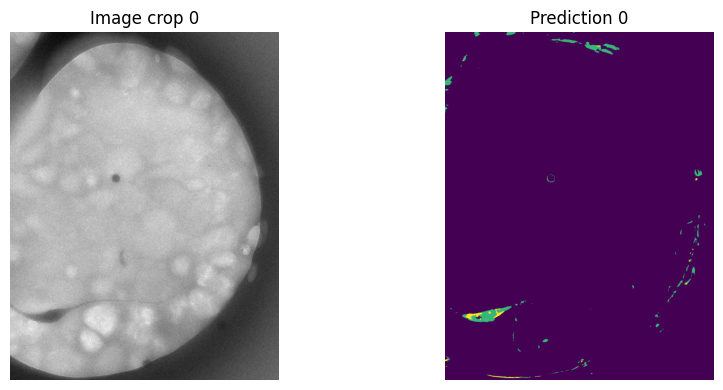

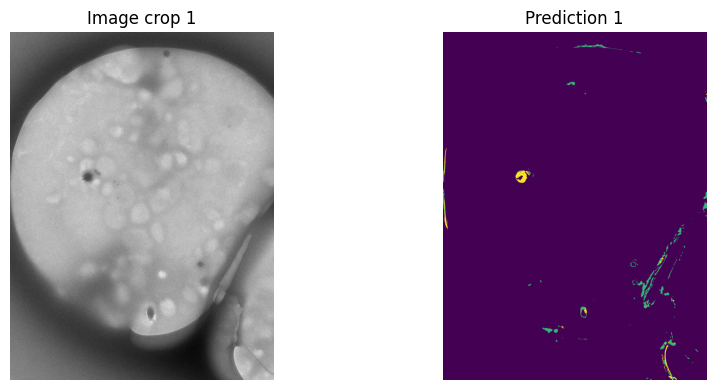

In [15]:
import matplotlib.pyplot as plt

crop_dict = crops[test_images[2]]

for i, (img_crop, prediction) in enumerate(
    zip(crop_dict["img_crops"], crop_dict["predictions"])
):
    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(img_crop, cmap="gray")
    plt.title(f"Image crop {i}")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(prediction)
    plt.title(f"Prediction {i}")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

In [28]:
Path.cwd()

PosixPath('/home/xgupke/Documents/projects/EmmaElinTrombocytes/pixel_classifier')